Travelling Salesman Algorithm

In [2]:
import time

def tsp(dist, n):
    INF = float("inf")
    dp = [[INF] * n for _ in range(1 << n)]
    parent = [[-1] * n for _ in range(1 << n)]

    # Start from city 0
    dp[1][0] = 0

    for mask in range(1 << n):
        for u in range(n):
            if not (mask & (1 << u)):
                continue
            if dp[mask][u] == INF:
                continue

            for v in range(n):
                if mask & (1 << v):
                    continue

                new_mask = mask | (1 << v)
                new_cost = dp[mask][u] + dist[u][v]

                if new_cost < dp[new_mask][v]:
                    dp[new_mask][v] = new_cost
                    parent[new_mask][v] = u

    # Return to starting city (city 0)
    full_mask = (1 << n) - 1
    min_cost = INF
    last_city = -1

    for u in range(1, n):
        cost = dp[full_mask][u] + dist[u][0]
        if cost < min_cost:
            min_cost = cost
            last_city = u

    # Reconstruct optimal route
    route = []
    mask = full_mask
    city = last_city

    while city != -1:
        route.append(city)
        prev = parent[mask][city]
        mask ^= (1 << city)
        city = prev

    route.reverse()
    route.append(0)

    return min_cost, route


n = int(input("Enter number of cities: "))

if n < 2:
    print("Please enter at least 2 cities.")
else:
    print("Enter the distance matrix row by row:")
    dist = []

    for i in range(n):
        row = list(map(int, input().split()))
        dist.append(row)

    start_time = time.perf_counter()

    min_cost, route = tsp(dist, n)

    end_time = time.perf_counter()

    print("Minimum tour cost:", min_cost)
    print("Optimal route:",
          " -> ".join(str(city) for city in route))
    print("Execution time:",
          f"{end_time - start_time:.8f} seconds")

Enter number of cities: 4
Enter the distance matrix row by row:
0 10 15 20
10 0 35 25
15 35 0 30
20 25 30 0
Minimum tour cost: 80
Optimal route: 0 -> 2 -> 3 -> 1 -> 0
Execution time: 0.00005091 seconds


Output:

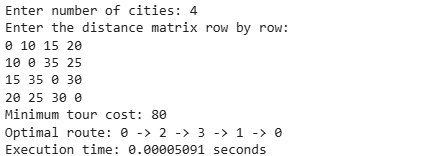

Readme:

Travelling Salesman Problem (TSP)

This Python program uses Dynamic Programming with Bitmasking to find the minimum-cost tour that visits every city once and returns to the starting city.

Time Complexity: O(n² × 2ⁿ) | Space Complexity: O(n × 2ⁿ); measures execution time and displays the optimal route.